# Lake Victoria Fish Stock & Export Risk Model

A fish-export cooperative in Jinja wants to assess harvest sustainability and revenue risk. The reusable simulation classes live in [`src/fish_stock.py`](src/fish_stock.py); this notebook explores the Fibonacci baseline, logistic stock dynamics, uncertain prices, scenario results, and a closed season.

## Units and modelling choices

Fish stock and harvest are measured in tonnes. The harvest rate `h` is interpreted as the fraction of standing stock harvested each open week, as required by the recurrence. Prices are UGX/kg, so weekly revenue is harvested tonnes × 1,000 kg/tonne × weekly price. All price results are illustrative; real harvest limits, seasonality, recruitment, age structure, costs and market dependence should be incorporated before operational decisions.

In [11]:
import matplotlib.pyplot as plt
import numpy as np

from src.fish_stock import FibonacciStockBaseline, FishStock, PriceModel, RiskAssessor

GROWTH_RATE = 0.4
CARRYING_CAPACITY_TONNES = 10_000
INITIAL_STOCK_TONNES = 4_000
WEEKS_PER_YEAR = 52
MONTE_CARLO_PATHS = 1_000
RANDOM_SEED = 20261010
HARVEST_RATES = (0.05, 0.10, 0.20, 0.30)

## 1. Fibonacci numbers as a baseline

The earlier approach treated an unbounded Fibonacci sequence as fish stock. Generate 15 terms to see the growth pattern before replacing it with a population model.

In [12]:
fibonacci_stock = FibonacciStockBaseline.generate(15)
print("15 Fibonacci terms:", fibonacci_stock)

15 Fibonacci terms: [1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377, 610]


### Why Fibonacci growth is biologically unrealistic

A Fibonacci sequence grows without an upper bound, while a fish population is constrained by food, habitat, oxygen, predation and fishing pressure. The sequence has no units, recruitment process, mortality, carrying capacity or harvest mechanism. Its growth accelerates according to a mathematical recurrence unrelated to fish biology. It therefore cannot establish a sustainable harvest level or a plausible stock trajectory.

## 2. Discrete logistic stock model

The model follows `N(t+1) = N(t) + r N(t)(1 − N(t)/K) − h N(t)`. Logistic growth slows near the carrying capacity `K`; harvest removes a fraction `h` of the standing stock each open week. For constant `h < r`, the positive equilibrium is `K(1 − h/r)` and equilibrium harvest is `hK(1 − h/r)`. Maximizing that equilibrium yield gives the theoretical maximum sustainable yield `MSY = rK/4` at `h = r/2`.

In [13]:
reference_stock = FishStock(
    harvest_rate=0.10,
    intrinsic_growth_rate=GROWTH_RATE,
    carrying_capacity=CARRYING_CAPACITY_TONNES,
    initial_stock=INITIAL_STOCK_TONNES,
)
maximum_sustainable_yield = reference_stock.maximum_sustainable_yield
stock_trajectory, weekly_harvest = reference_stock.simulate(weeks=WEEKS_PER_YEAR)
print(f"Initial stock: {stock_trajectory[0]:,.0f} tonnes")
print(f"Final stock after 52 weeks at h=0.10: {stock_trajectory[-1]:,.2f} tonnes")
print(f"Theoretical MSY: {maximum_sustainable_yield:,.0f} tonnes/week")
print(f"Mean harvest at h=0.10: {np.mean(weekly_harvest):,.2f} tonnes/week")

Initial stock: 4,000 tonnes
Final stock after 52 weeks at h=0.10: 7,500.00 tonnes
Theoretical MSY: 1,000 tonnes/week
Mean harvest at h=0.10: 718.51 tonnes/week


## 3. Harvest-rate scenario analysis

Simulate one year for each requested weekly harvest rate. Report final stock, total annual catch and average weekly catch against the theoretical MSY. The MSY is a long-run equilibrium result, so a 52-week total starting below equilibrium need not equal 52 × MSY even at the maximizing rate.

In [14]:
scenario_stock = {}
for harvest_rate in HARVEST_RATES:
    model = FishStock(
        harvest_rate=harvest_rate,
        intrinsic_growth_rate=GROWTH_RATE,
        carrying_capacity=CARRYING_CAPACITY_TONNES,
        initial_stock=INITIAL_STOCK_TONNES,
    )
    stocks, harvests = model.simulate(weeks=WEEKS_PER_YEAR)
    scenario_stock[harvest_rate] = {"stocks": stocks, "harvests": harvests}
    print(
        f"h={harvest_rate:.2f}: final stock={stocks[-1]:,.2f} tonnes | "
        f"annual harvest={np.sum(harvests):,.2f} tonnes | "
        f"mean={np.mean(harvests):,.2f} tonnes/week | "
        f"MSY={maximum_sustainable_yield:,.0f} tonnes/week"
    )

h=0.05: final stock=8,750.00 tonnes | annual harvest=21,714.61 tonnes | mean=417.59 tonnes/week | MSY=1,000 tonnes/week
h=0.10: final stock=7,500.00 tonnes | annual harvest=37,362.51 tonnes | mean=718.51 tonnes/week | MSY=1,000 tonnes/week
h=0.20: final stock=4,999.99 tonnes | annual harvest=50,871.71 tonnes | mean=978.30 tonnes/week | MSY=1,000 tonnes/week
h=0.30: final stock=2,503.72 tonnes | annual harvest=42,461.02 tonnes | mean=816.56 tonnes/week | MSY=1,000 tonnes/week


### Interpreting MSY and the harvest scenarios

With `r = 0.4` and `K = 10,000`, the equilibrium yield curve is maximized at `h = r/2 = 0.20`, where equilibrium stock is `K/2 = 5,000` tonnes and yield is 1,000 tonnes/week. A rate below 0.20 gives a higher equilibrium stock but lower equilibrium yield; a rate above 0.20 lowers both equilibrium stock and yield. These rates are weekly fractions in this assignment's recurrence, not annual quotas, and the one-year simulation reflects its initial stock as well as its long-run equilibrium.

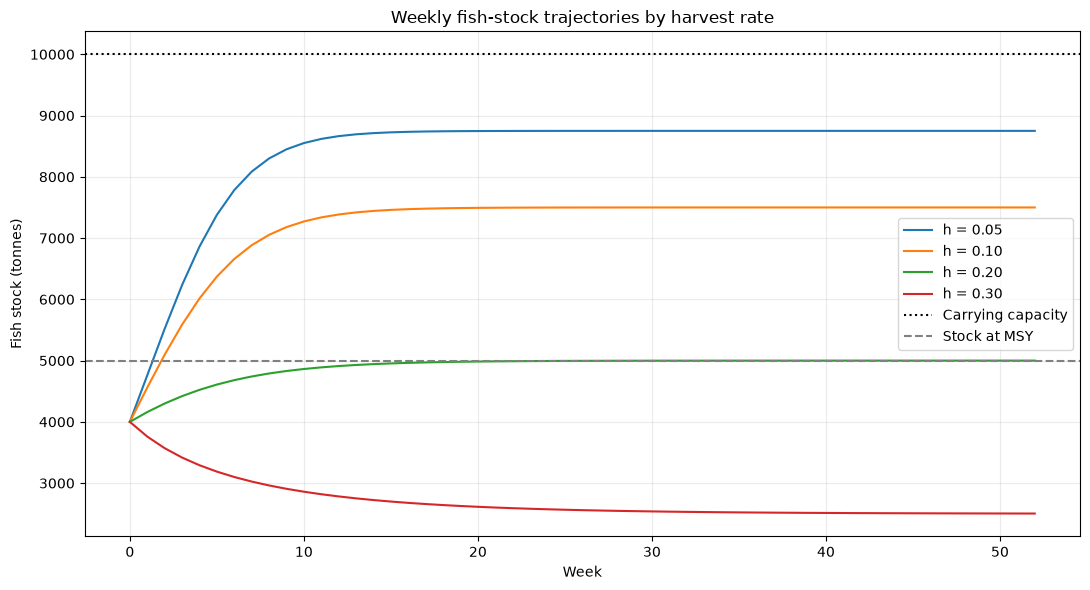

In [15]:
weeks = np.arange(WEEKS_PER_YEAR + 1)
figure, axis = plt.subplots(figsize=(11, 6))
for harvest_rate, result in scenario_stock.items():
    axis.plot(weeks, result["stocks"], label=f"h = {harvest_rate:.2f}")
axis.axhline(CARRYING_CAPACITY_TONNES, color="black", linestyle=":", label="Carrying capacity")
axis.axhline(CARRYING_CAPACITY_TONNES / 2, color="gray", linestyle="--", label="Stock at MSY")
axis.set_xlabel("Week")
axis.set_ylabel("Fish stock (tonnes)")
axis.set_title("Weekly fish-stock trajectories by harvest rate")
axis.grid(alpha=0.25)
axis.legend()
figure.tight_layout()
plt.show()

## 4. Seeded bounded export-price random walk

The price starts at UGX 12,000/kg and receives normally distributed weekly increments with a standard deviation of UGX 500/kg. Prices are clipped to the stated UGX 9,000–16,000 bounds. The fixed seed makes the Monte Carlo experiment reproducible; this simple random walk is an assumption, not a fitted market-price forecast.

In [16]:
price_model = PriceModel(
    starting_price=12_000,
    lower_bound=9_000,
    upper_bound=16_000,
    weekly_volatility=500,
    seed=RANDOM_SEED,
)
price_paths = price_model.simulate_prices(
    weeks=WEEKS_PER_YEAR,
    paths=MONTE_CARLO_PATHS,
)
print(f"Simulated price paths: {price_paths.shape[0]:,}")
print(f"Price range observed: UGX {price_paths.min():,.2f}–{price_paths.max():,.2f} per kg")
print("First path, first 10 weekly prices:", price_paths[0, :10].round(2))

Simulated price paths: 1,000
Price range observed: UGX 9,000.00–16,000.00 per kg
First path, first 10 weekly prices: [12000.   12494.27 12866.91 13015.26 12805.87 12308.43 11679.85 13274.23
 13309.75 12988.89]


## 5. Weekly and annual revenue distributions

Each price path is combined with the same deterministic harvest trajectory for a scenario. Weekly harvest in tonnes is converted to kilograms before multiplying by price. Annual revenue for each Monte Carlo path is the sum of its 52 weekly revenues. Revenue variance is measured in UGX², not UGX; its numeric value also depends on catch scale and the chosen currency denomination. A raw threshold such as 50,000 therefore has no useful interpretation without units, scale, and calibration. The coefficient of variation (CV = sample standard deviation / mean) is dimensionless and allows a relative-volatility classification.

In [17]:
annual_revenue = {}
weekly_revenue = {}
scenario_summary = {}
for harvest_rate, result in scenario_stock.items():
    weekly_revenue[harvest_rate] = (
        result["harvests"][None, :] * 1_000 * price_paths
    )
    annual_revenue[harvest_rate] = np.sum(weekly_revenue[harvest_rate], axis=1)
    summary = RiskAssessor.summarize(annual_revenue[harvest_rate])
    summary["risk_class"] = RiskAssessor.classify_cv(summary["cv"])
    summary["var_5pct"] = RiskAssessor.revenue_var(annual_revenue[harvest_rate])
    scenario_summary[harvest_rate] = summary

print(
    f"{'h':>5} {'Final stock (t)':>18} {'Mean annual harvest (t)':>25} "
    f"{'Mean annual revenue (UGX)':>28} {'CV':>9} {'Risk':>10}"
)
for harvest_rate, result in scenario_stock.items():
    summary = scenario_summary[harvest_rate]
    print(
        f"{harvest_rate:5.2f} {result['stocks'][-1]:18,.2f} "
        f"{np.mean(result['harvests']):25,.2f} "
        f"{summary['mean']:28,.0f} {summary['cv']:9.3f} "
        f"{summary['risk_class']:>10}"
    )

    h    Final stock (t)   Mean annual harvest (t)    Mean annual revenue (UGX)        CV       Risk
 0.05           8,750.00                    417.59              262,753,738,471     0.141   Moderate
 0.10           7,500.00                    718.51              452,079,651,477     0.140   Moderate
 0.20           4,999.99                    978.30              615,428,122,537     0.138   Moderate
 0.30           2,503.72                    816.56              513,385,368,491     0.129   Moderate


### Risk rule and revenue statistics

For a transparent screening rule, CV ≤ 10% is labelled low relative revenue variability, 10–25% moderate, and >25% high. These are illustrative management bands, not statistically calibrated regulatory thresholds; a cooperative should set them against its cash-flow tolerance and historical performance. The statistics below describe the Monte Carlo distribution of annual revenue for the `h = 0.10` case and include mean, median, sample variance, sample standard deviation and CV.

In [18]:
focus_rate = 0.10
focus_revenue = annual_revenue[focus_rate]
focus_stats = RiskAssessor.summarize(focus_revenue)
print(f"Annual revenue statistics at h={focus_rate:.2f} ({MONTE_CARLO_PATHS:,} paths)")
print(f"Mean:       UGX {focus_stats['mean']:,.0f}")
print(f"Median:     UGX {focus_stats['median']:,.0f}")
print(f"Variance:   {focus_stats['variance']:,.0f} UGX²")
print(f"Std. dev.:  UGX {focus_stats['stdev']:,.0f}")
print(f"CV:         {focus_stats['cv']:.2%}")
print(f"Risk class: {RiskAssessor.classify_cv(focus_stats['cv'])}")
print(f"5% lower-tail annual revenue VaR: UGX {RiskAssessor.revenue_var(focus_revenue):,.0f}")

Annual revenue statistics at h=0.10 (1,000 paths)
Mean:       UGX 452,079,651,477
Median:     UGX 448,883,748,989
Variance:   4,011,759,287,985,858,674,688 UGX²
Std. dev.:  UGX 63,338,450,312
CV:         14.01%
Risk class: Moderate
5% lower-tail annual revenue VaR: UGX 357,879,120,291


## 6. Annual revenue histogram and 5% VaR

Here, “5% VaR of revenue” means the 5th percentile of annual revenue: under the simulated model, 5% of outcomes are at or below the marked amount. This lower-tail revenue quantile is not the conventional loss VaR sign convention, so it is explicitly reported as revenue at risk.

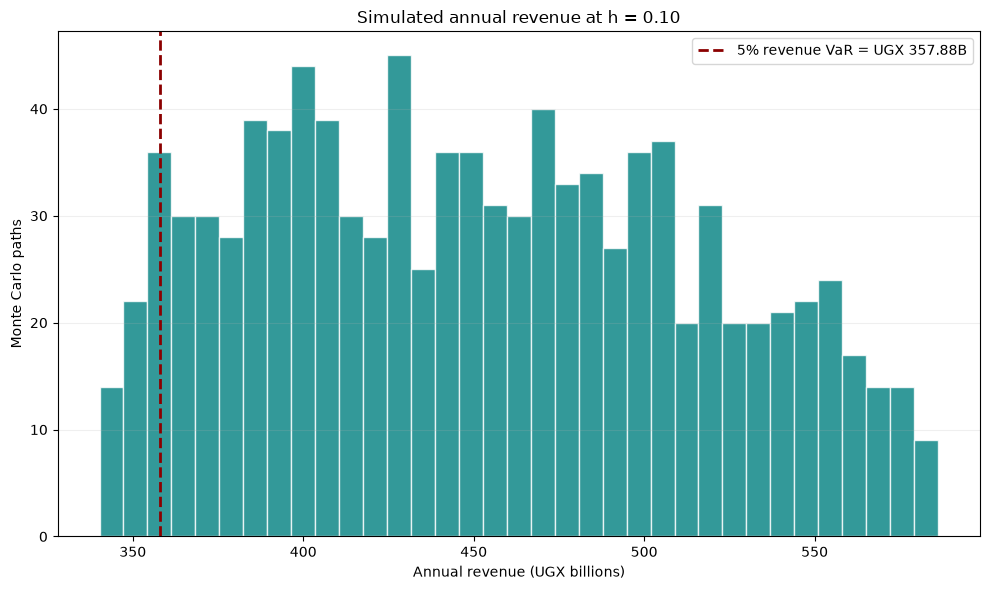

In [19]:
var_5 = RiskAssessor.revenue_var(focus_revenue, confidence=0.95)
figure, axis = plt.subplots(figsize=(10, 6))
axis.hist(focus_revenue / 1e9, bins=35, color="teal", alpha=0.8, edgecolor="white")
axis.axvline(var_5 / 1e9, color="darkred", linestyle="--", linewidth=2, label=f"5% revenue VaR = UGX {var_5 / 1e9:.2f}B")
axis.set_xlabel("Annual revenue (UGX billions)")
axis.set_ylabel("Monte Carlo paths")
axis.set_title("Simulated annual revenue at h = 0.10")
axis.legend()
axis.grid(axis="y", alpha=0.2)
figure.tight_layout()
plt.show()

## 7. Extension: an eight-week closed season over five years

Compare continuous harvesting with a closed season during the first eight weeks of every 52-week year, using `h = 0.10`. Both cases use the same seeded price paths so differences in the paired revenue distributions come from harvest timing and stock recovery, rather than different random prices. Report the mean five-year revenue, mean paired revenue change, and final stock for both strategies. The closure is a simple policy illustration; the timing and biological effect need local evidence.

In [20]:
closed_season_years = 5
long_run_weeks = closed_season_years * WEEKS_PER_YEAR
long_run_prices = price_model.simulate_prices(
    weeks=long_run_weeks,
    paths=MONTE_CARLO_PATHS,
    seed=RANDOM_SEED + 1,
)
closure_comparison = {}
for label, closed_weeks in (("No closed season", 0), ("8-week closure", 8)):
    model = FishStock(
        harvest_rate=0.10,
        intrinsic_growth_rate=GROWTH_RATE,
        carrying_capacity=CARRYING_CAPACITY_TONNES,
        initial_stock=INITIAL_STOCK_TONNES,
    )
    stocks, harvests = model.simulate(
        weeks=long_run_weeks,
        closed_season_weeks=closed_weeks,
        weeks_per_year=WEEKS_PER_YEAR,
    )
    revenues = np.sum(harvests[None, :] * 1_000 * long_run_prices, axis=1)
    closure_comparison[label] = {
        "stocks": stocks,
        "harvests": harvests,
        "revenues": revenues,
        "mean_revenue": float(np.mean(revenues)),
        "final_stock": float(stocks[-1]),
    }

revenue_change = (
    closure_comparison["8-week closure"]["revenues"]
    - closure_comparison["No closed season"]["revenues"]
)
for label, result in closure_comparison.items():
    print(
        f"{label}: mean 5-year revenue=UGX {result['mean_revenue']:,.0f}; "
        f"final stock={result['final_stock']:,.2f} tonnes"
    )
print(
    f"Mean paired revenue change from closure: UGX {np.mean(revenue_change):,.0f} "
    f"({np.mean(revenue_change) / closure_comparison['No closed season']['mean_revenue']:.2%})"
)

No closed season: mean 5-year revenue=UGX 2,376,131,035,613; final stock=7,500.00 tonnes
8-week closure: mean 5-year revenue=UGX 2,069,238,991,839; final stock=7,500.00 tonnes
Mean paired revenue change from closure: UGX -306,892,043,774 (-12.92%)


## Conclusions

- Fibonacci numbers are a poor stock model because they grow without a carrying capacity or biological mechanisms. The discrete logistic model includes density-limited growth and an explicit harvest fraction.
- The theoretical equilibrium MSY is **1,000 tonnes/week**, attained at a weekly harvest fraction of **0.20** for the stated parameters. One-year scenario totals differ from this equilibrium yield because the initial stock is 4,000 tonnes and the system has not necessarily reached equilibrium.
- Revenue risk is summarized with CV, a scale-free measure, rather than a raw variance cutoff. Revenue variance has units of UGX², so a bare threshold of 50,000 is dimensionally and economically ungrounded.
- The Monte Carlo 5% revenue VaR is the lower-tail 5th percentile under the seeded, bounded random-walk price assumptions—not a guarantee or a market-calibrated forecast.
- The closed-season comparison quantifies this model's five-year trade-off between foregone harvest during closure and stock recovery. A real policy decision needs validated fishery data and conservation objectives.

Interpret all results as demonstrations of the specified model and assumptions, not as official Lake Victoria stock assessments or harvest recommendations.